In [107]:
# 문제1. 호텔 예약 데이터 분석 통합 
#1-1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
booking_raw = pd.read_csv(r"C:\Users\syeon\OneDrive\Desktop\hotel_bookings.csv")


In [108]:
# 처음 5개 행 수.
#1-2(1)
display(booking_raw.head()) 

,booking_id,lead_time,weekend_nights,weekday_nights,adults,children,room_type,daily_rate,booking_channel,is_canceled
0,HB0204,15.0,2.0,5.0,2.0,1.0,Deluxe,180000.0,Direct,0
1,HB0267,7.0,0.0,4.0,2.0,0.0,Standard,130000.0,Direct,0
2,HB0153,28.0,2.0,4.0,1.0,0.0,Standard,70000.0,Online,0
3,HB0010,30.0,2.0,3.0,2.0,2.0,Standard,130000.0,Online,0
4,HB0234,171.0,0.0,4.0,2.0,1.0,Standard,120000.0,Agency,0


In [109]:
# 행과 열 개수
#1-2(2)
display(booking_raw.shape) 

(300, 10)

In [110]:
#각 열의 자료형 확인

#1-3
booking_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   booking_id       300 non-null    str    
 1   lead_time        298 non-null    float64
 2   weekend_nights   298 non-null    float64
 3   weekday_nights   298 non-null    float64
 4   adults           298 non-null    float64
 5   children         298 non-null    float64
 6   room_type        296 non-null    str    
 7   daily_rate       296 non-null    float64
 8   booking_channel  296 non-null    str    
 9   is_canceled      300 non-null    int64  
dtypes: float64(6), int64(1), str(3)
memory usage: 23.6 KB


In [111]:
# 수치형 열의 기숥통계량 출력
#1-4
display(booking_raw.describe())

,lead_time,weekend_nights,weekday_nights,adults,children,daily_rate,is_canceled
count,298.000000,298.000000,298.000000,298.000000,298.000000,296.000000,300.000000
mean,47.677852,0.942953,2.953020,1.768456,0.422819,166587.837838,0.233333
std,51.739801,0.812425,1.448722,0.605873,0.683438,137061.828387,0.423659
min,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-10000.000000,0.000000
25%,8.000000,0.000000,2.000000,1.000000,0.000000,100000.000000,0.000000
50%,23.000000,1.000000,3.000000,2.000000,0.000000,120000.000000,0.000000
75%,78.750000,2.000000,4.000000,2.000000,1.000000,180000.000000,0.000000
max,179.000000,2.000000,5.000000,3.000000,2.000000,1000000.000000,1.000000


In [112]:
# 결측치 개수 및 결측률(%)
#1-5
display(pd.DataFrame({"결측치 개수": booking_raw.isna().sum(),"결측률(%)": booking_raw.isna().mean() * 100}))

,결측치 개수,결측률(%)
booking_id,0,0.000000
lead_time,2,0.666667
weekend_nights,2,0.666667
weekday_nights,2,0.666667
adults,2,0.666667
children,2,0.666667
room_type,4,1.333333
daily_rate,4,1.333333
booking_channel,4,1.333333
is_canceled,0,0.000000


In [113]:
#취소 예약과 미취소 예약의 건수 및 전체 예약 대비 비율
#1-6
# 0=미취소, 1= 취소
display(booking_raw["is_canceled"].value_counts(dropna=False))

display(booking_raw["is_canceled"].value_counts(normalize=True)*100)


is_canceled
0    230
1     70
Name: count, dtype: int64

is_canceled
0    76.666667
1    23.333333
Name: proportion, dtype: float64

In [114]:
#1-7 정제가 필요한 항목
#여러 열에 결측값이 있어 정제가 필요하다.
# 그리고 어떤 열에는 음수가 있어서 호텔 요금과 인원수 일수 등이 음수가 있어서 오류값 처리가 필요하다.
# 1000000 daliy_rate가 있어서 이상치를 인지 확인할 필요가 있다.

In [115]:
# 문제2. 결측치와 명확한 오류 값 처리
#2-1 복사하여 생성
booking_clean = booking_raw.copy()


In [116]:
display(booking_clean.loc[booking_clean["lead_time"]<0,["booking_id","lead_time"]])

display(booking_clean.loc[booking_clean["weekend_nights"]<0,["booking_id","weekend_nights"]])

display(booking_clean.loc[booking_clean["weekday_nights"]<0,["booking_id","weekday_nights"]])

display(booking_clean.loc[booking_clean["adults"]<0,["booking_id","adults"]])

display(booking_clean.loc[booking_clean["children"]<0,["booking_id","children"]])

display(booking_clean.loc[booking_clean["daily_rate"]<=0,["booking_id","daily_rate"]])

,booking_id,lead_time
219,HB0041,-1.0


,booking_id,weekend_nights
173,HB0042,-1.0


,booking_id,weekday_nights
25,HB0043,-1.0


,booking_id,adults
243,HB0044,-1.0


,booking_id,children
216,HB0045,-1.0


,booking_id,daily_rate
13,HB0046,-10000.0
38,HB0047,0.0


In [117]:
# 결측치 처리 밑 전 후 개수 출력
booking_clean.loc[booking_clean["lead_time"]<0, "lead_time"] = np.nan
booking_clean.loc[booking_clean["weekend_nights"]<0, "weekend_nights"] = np.nan
booking_clean.loc[booking_clean["weekday_nights"]<0, "weekday_nights"] = np.nan
booking_clean.loc[booking_clean["adults"]<0, "adults"] = np.nan
booking_clean.loc[booking_clean["children"]<0, "children"] = np.nan
booking_clean.loc[booking_clean["daily_rate"]<=0, "daily_rate"] = np.nan

print("처리 전:",len(booking_raw))

booking_clean= booking_clean.dropna(subset=["lead_time","weekend_nights","weekday_nights","adults","children"])

print("처리 후:",len(booking_clean))

print("제외한 행의 수",len(booking_raw)-len(booking_clean))

처리 전: 300
처리 후: 285
제외한 행의 수 15


In [118]:
#결측치 확인 및 처리 및 대체 
dr_median = booking_clean["daily_rate"].median() # 중앙값을 선택한 이유는 100만원의 비용 하나가 있어 평균에 영향을 받기에 중앙값을 선택함.
booking_clean["daily_rate"] = booking_clean["daily_rate"].fillna(dr_median)
booking_clean["room_type"] = booking_clean["room_type"].fillna("Unknown") #범주형 데이터에는 다른 최빈값이나 그런 걸 넣으면 확실하지 않은 정보이기에 Unknown으로 표시
booking_clean["booking_channel"] = booking_clean["booking_channel"].fillna("Unknown")

display(booking_clean.isna().sum())
display((booking_clean["lead_time"]<0).any())
display((booking_clean["weekend_nights"]<0).any())
display((booking_clean["weekday_nights"]<0).any())
display((booking_clean["adults"]<0).any())
display((booking_clean["children"]<0).any())
display((booking_clean["daily_rate"]<=0).any())
 # 일수와 인원수의 결측치를 제거 하지 않고 채우게 되면 객실 요금들이 영향을 받기 떄문에 제거 하는 것이 맞다고 생각합니다. 통계가 왜곡 될 수 있다고 생각합니다.

booking_id         0
lead_time          0
weekend_nights     0
weekday_nights     0
adults             0
children           0
room_type          0
daily_rate         0
booking_channel    0
is_canceled        0
dtype: int64

np.False_

np.False_

np.False_

np.False_

np.False_

np.False_

In [119]:
# 문제 3. 객실 요금의 이상치 후보 탐지 및 처리
Q1 = booking_clean["daily_rate"].quantile(0.25)
Q3 = booking_clean["daily_rate"].quantile(0.75)

IQR = Q3-Q1
하한 = Q1- 1.5*IQR
상한 = Q3+ 1.5*IQR

print(Q1)
print(Q3)
print(IQR)
print(f"{하한}")
print(f"{상한}")

100000.0
180000.0
80000.0
-20000.0
300000.0


In [120]:
outlier_mask = (booking_clean["daily_rate"]<하한) | (booking_clean["daily_rate"]>상한)
print(outlier_mask.sum()) # 이상치 후보 건수
print(outlier_mask.mean()*100) # 후보 비율


26
9.12280701754386


In [121]:
display(booking_clean.loc[outlier_mask,["booking_id","room_type","daily_rate"]])


,booking_id,room_type,daily_rate
7,HB0110,Suite,550000.0
8,HB0006,Suite,450000.0
14,HB0183,Suite,350000.0
32,HB0034,Suite,640000.0
37,HB0091,Suite,800000.0
57,HB0093,Suite,1000000.0
67,HB0257,Suite,420000.0
81,HB0155,Suite,560000.0
85,HB0115,Suite,480000.0
98,HB0275,Suite,580000.0


In [122]:
#원래 요금과 처리된 요금의 최솟값 중앙값 최댓값 비교

booking_clean["daily_rate_processed"] = booking_clean["daily_rate"]

booking_clean[["daily_rate","daily_rate_processed"]].agg(["min","median","max"])

,daily_rate,daily_rate_processed
min,70000.0,70000.0
median,120000.0,120000.0
max,1000000.0,1000000.0


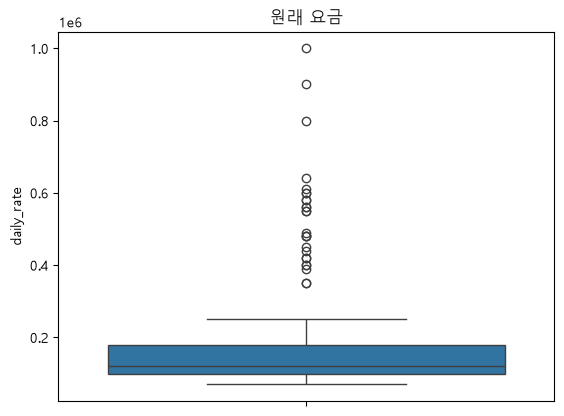

In [123]:
# 원래 요금의 박스플롯 그래프
sns.boxplot(data=booking_clean,y= "daily_rate")
plt.title("원래 요금")
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
plt.show()

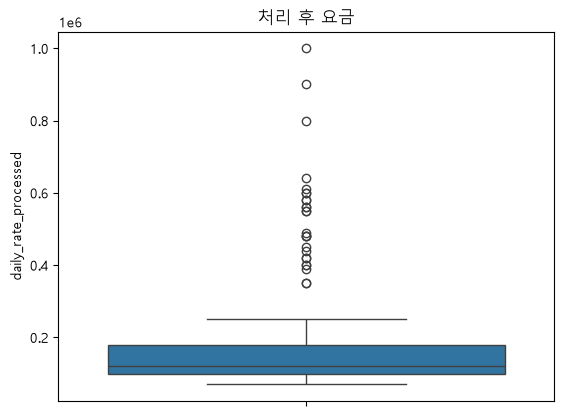

In [124]:
# 처리된 후 요금의 박스플롯 그래프

sns.boxplot(data=booking_clean,y="daily_rate_processed")
plt.title("처리 후 요금")
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
plt.show()

In [125]:
# 이상치 후보 대부분이 Suite 룸이 였기 때문에 원래 요금을 유지 할 수 밖에 없었습니다. 
# 상황에 따라 특히 스위트 룸이라는 건 거의 프리미엄 룸으로 볼 정도로 매 타이밍 매 시간마다 가격이 달라질 수 있는 요금이기 떄문입니다
# IQR 범위 밖이더라도 상황에 따라 비용이 바뀔 수 있는 게 호텔 객실 비용이고 이것만으로 오류라고 볼 수 없을 것 같습니다.


In [126]:
# 파생 변수 생성
booking_clean["total_nights"] = booking_clean["weekend_nights"]+booking_clean["weekday_nights"]
booking_clean["total_guests"] = booking_clean["adults"]+booking_clean["children"]
booking_clean["estimated_room_amount"] = booking_clean["daily_rate"]*booking_clean["total_nights"]

booking_clean.loc[(0<=booking_clean["lead_time"])& (booking_clean["lead_time"]<=7),"lead_time_group"] = "Within7Days"
booking_clean.loc[(7<booking_clean["lead_time"])&(booking_clean["lead_time"]<=30),"lead_time_group"] = "8to30Days"
booking_clean.loc[30<booking_clean["lead_time"],"lead_time_group"] = "Over30Days"

In [127]:
zero_mask = (booking_clean["total_nights"]==0)|(booking_clean["total_guests"]==0)

display(booking_clean.loc[zero_mask,"booking_id"])
print(zero_mask.sum())

169    HB0052
251    HB0054
261    HB0053
271    HB0051
Name: booking_id, dtype: str

4


In [128]:
booking_clean = booking_clean.loc[~zero_mask].copy()
len(booking_clean)

281

In [129]:
display((booking_clean[[
"booking_id","lead_time","weekend_nights","weekday_nights","adults","children","room_type","daily_rate",
"booking_channel","is_canceled","total_nights","total_guests","estimated_room_amount","lead_time_group"]]).head(10))

,booking_id,lead_time,weekend_nights,weekday_nights,adults,children,room_type,daily_rate,booking_channel,is_canceled,total_nights,total_guests,estimated_room_amount,lead_time_group
0,HB0204,15.0,2.0,5.0,2.0,1.0,Deluxe,180000.0,Direct,0,7.0,3.0,1260000.0,8to30Days
1,HB0267,7.0,0.0,4.0,2.0,0.0,Standard,130000.0,Direct,0,4.0,2.0,520000.0,Within7Days
2,HB0153,28.0,2.0,4.0,1.0,0.0,Standard,70000.0,Online,0,6.0,1.0,420000.0,8to30Days
3,HB0010,30.0,2.0,3.0,2.0,2.0,Standard,130000.0,Online,0,5.0,4.0,650000.0,8to30Days
4,HB0234,171.0,0.0,4.0,2.0,1.0,Standard,120000.0,Agency,0,4.0,3.0,480000.0,Over30Days
5,HB0227,143.0,0.0,5.0,2.0,2.0,Standard,100000.0,Direct,0,5.0,4.0,500000.0,Over30Days
6,HB0197,91.0,2.0,1.0,1.0,1.0,Deluxe,160000.0,Online,1,3.0,2.0,480000.0,Over30Days
7,HB0110,27.0,1.0,2.0,1.0,0.0,Suite,550000.0,Agency,0,3.0,1.0,1650000.0,8to30Days
8,HB0006,6.0,2.0,2.0,2.0,0.0,Suite,450000.0,Direct,1,4.0,2.0,1800000.0,Within7Days
9,HB0176,127.0,1.0,1.0,3.0,0.0,Standard,80000.0,Direct,1,2.0,3.0,160000.0,Over30Days


In [130]:

display(booking_clean.loc[booking_clean["lead_time"].isin([7,30]),["lead_time","lead_time_group"]])


,lead_time,lead_time_group
1,7.0,Within7Days
3,30.0,8to30Days
32,7.0,Within7Days
42,7.0,Within7Days
45,30.0,8to30Days
91,30.0,8to30Days
121,30.0,8to30Days
164,7.0,Within7Days
190,7.0,Within7Days
283,7.0,Within7Days


In [131]:
# 문제 4. 파생변수 활용 설명

# total_nights: 예약별 총 숙박일수를 파악하여 객실 운영 계획에 활용할 수 있다.

# total_guests: 총 투숙 인원에 맞춰 수건과 세면도구 등 필요한 물품을 준비할 수 있다.

# estimated_room_amount: 예약별 예상 객실 요금 총액을 비교하여
# 금액이 큰 예약부터 우선 확인하는 데 활용할 수 있다.

# lead_time_group: 예약일부터 예정 입실일까지 남은 일수의 구간별로
# 객실 요금 차이가 있는지 비교할 수 있다.
# 다만 차이가 있더라도 예약 시점이 원인이라고 단정할 수는 없다.

# estimated_room_amount는 취소·환불·추가 요금 등이 반영되지 않은
# 예약 기준의 예상 금액이므로 실제 매출이라고 볼 수 없다.

In [132]:
#문제 5. 사전 확인 대상 예약 추출

#5-1 조건을 만족하는 예약을 추출하여 selected에 저장

selected_mask = (booking_clean["is_canceled"] == 0) & (booking_clean["lead_time"]>= 60) & (booking_clean["total_nights"]>=3) & (booking_clean["booking_channel"].isin(["Online","Agency"]))
selected = booking_clean.loc[selected_mask].copy()

#5-3 예상 객실 요금이 큰 순서대로 정렬하고 처음 10개 행 출력

selected[["booking_id","booking_channel","lead_time","total_nights","total_guests","estimated_room_amount"]].sort_values("estimated_room_amount",ascending=False).head(10)

,booking_id,booking_channel,lead_time,total_nights,total_guests,estimated_room_amount
198,HB0028,Online,154.0,4.0,2.0,1920000.0
149,HB0084,Online,157.0,6.0,3.0,1440000.0
50,HB0181,Agency,79.0,7.0,2.0,1260000.0
292,HB0122,Online,133.0,4.0,2.0,1000000.0
52,HB0240,Online,115.0,7.0,1.0,910000.0
78,HB0067,Online,60.0,5.0,2.0,900000.0
232,HB0292,Online,154.0,5.0,4.0,900000.0
93,HB0225,Agency,84.0,7.0,2.0,840000.0
41,HB0077,Agency,150.0,3.0,2.0,750000.0
140,HB0116,Online,92.0,4.0,2.0,720000.0


In [133]:
# 5-4 사전 확인 대상 예약의 전체 건수와 예상 객실 요금 합계

print(len(selected))
print(selected["estimated_room_amount"].sum())

#5-5 추출된 데이터가 네 가지 조건을 모두 만족하는지 코드로 확인

print((selected["is_canceled"]== 0).all())
print((selected["lead_time"]>= 60).all())
print((selected["total_nights"]>=3).all())
print((selected["booking_channel"].isin(["Online","Agency"])).all())

35
21510000.0
True
True
True
True


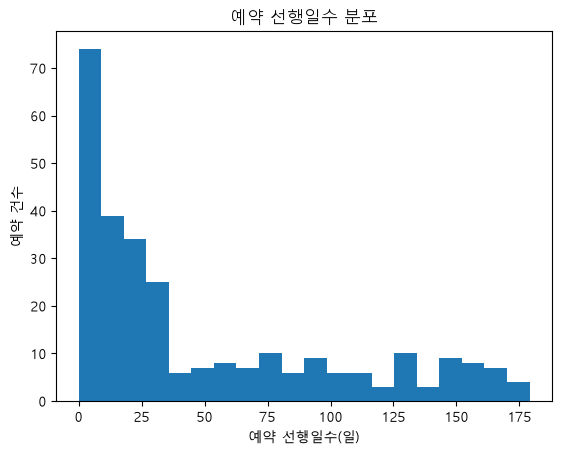

<Figure size 1000x500 with 0 Axes>

[  0.     8.95  17.9   26.85  35.8   44.75  53.7   62.65  71.6   80.55
  89.5   98.45 107.4  116.35 125.3  134.25 143.2  152.15 161.1  170.05
 179.  ]


In [134]:
# 문제 6. 예약 현황과 취소 비율 시각화

#lead_time 히스토그램 차드 생성

counts, edges, patches = plt.hist(booking_clean["lead_time"], bins=20)
plt.title("예약 선행일수 분포")
plt.xlabel("예약 선행일수(일)")
plt.ylabel("예약 건수")
plt.figure(figsize=(10,5))
plt.show()
print(edges)

In [135]:
#예약 선행일수가 짧은 구간에 예약이 집중되어 있으며, 특히 0~9일 구간의 예약 건수가 가장 많다. 선행일수가 긴 구간에도 예약이 분포하지만, 짧은 구간에 비해 건수가 적다고 보인다.

In [136]:
# 6-6 집단 별 예약 건수, 취소 건 수, 건수 취소율 표
channel_summary = pd.DataFrame({"예약건수": booking_clean.groupby("booking_channel")["is_canceled"].count(),
"취소 건수":booking_clean.groupby("booking_channel")["is_canceled"].sum(),
"취소율(%)":booking_clean.groupby("booking_channel")["is_canceled"].mean()*100})

display(channel_summary)

,예약건수,취소 건수,취소율(%)
booking_channel,,,
Agency,53,9,16.981132
Direct,83,13,15.662651
Online,141,42,29.787234
Unknown,4,1,25.000000


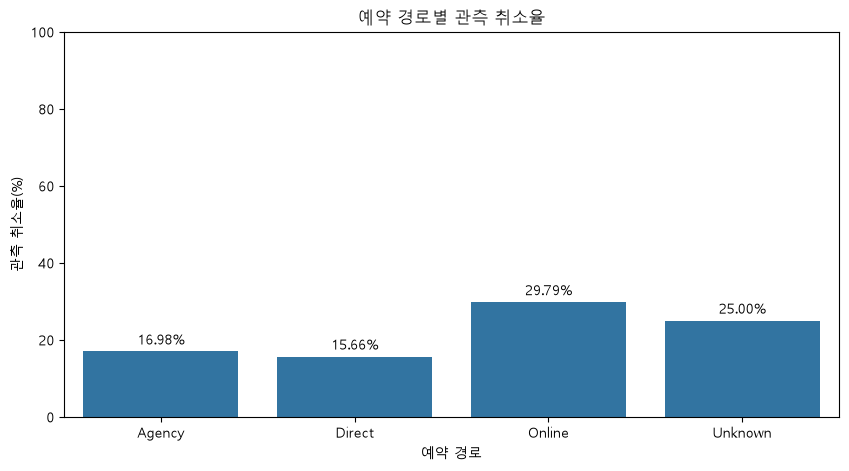

In [137]:
# 예약 경로별 취소 현황 비교
plt.figure(figsize=(10,5))
ax = sns.barplot(x=channel_summary.index,y=channel_summary["취소율(%)"])
plt.title("예약 경로별 관측 취소율")
plt.xlabel("예약 경로")
plt.ylabel("관측 취소율(%)")
plt.ylim(0,100)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
plt.show()

In [138]:
# 온라인으로 했을 시에 가장 취소율이 29.79%로 높았고, 
# 다이렉트로 했을시가 15.66%으로 가장 낮았으며, 
# Unknown은 4건중 1건의 취소 건으로 인해 %가 높게 나온 것이므로 해석할때 주의가 필요하다.

In [139]:
lead_summary = pd.DataFrame({"예약 건수":booking_clean.groupby("lead_time_group")["is_canceled"].count(),
                            "예약 취소 건수":booking_clean.groupby("lead_time_group")["is_canceled"].sum(),
                            "취소율(%)":booking_clean.groupby("lead_time_group")["is_canceled"].mean()*100})
group_order = ["Within7Days", "8to30Days", "Over30Days"]

lead_summary = lead_summary.reindex(group_order)

display(lead_summary)

,예약 건수,예약 취소 건수,취소율(%)
lead_time_group,,,
Within7Days,69,12,17.391304
8to30Days,100,13,13.000000
Over30Days,112,40,35.714286


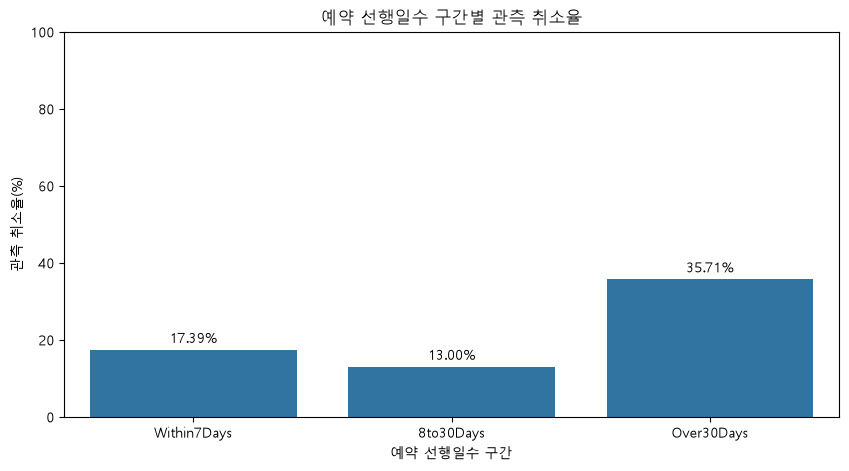

In [140]:
plt.figure(figsize=(10,5))
ax = sns.barplot(x=lead_summary.index,y=lead_summary["취소율(%)"])
plt.title("예약 선행일수 구간별 관측 취소율")
plt.xlabel("예약 선행일수 구간")
plt.ylabel("관측 취소율(%)")
plt.ylim(0,100)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
plt.show()

In [141]:
# Over 30 Days 인 경우에 35.71%로 가장 취소율이 높았고,
# 8to30days 의 경우에 13.00%로 가장 취소율이 낮았다.
# 미취소 되어있는 예약도 이후 취소될 수 있으므로, 이는 데이터 기준 시점의 관측 취소율이며 최종 취소율이나 인과관계를 단정하면 안된다.

In [142]:
#문제 7. 예약 운영팀에 분석 결과 전달

#음수 오류 값을 결측값으로 변경한 뒤, 일수·인원수에 결측값이 있는 행은 제외하고 요금 결측값은 중앙값으로 대체했으며, 범주형 열의 결측값은 "Unknown"으로 표시했습니다.
#예약은 약 0~9일의 선행일수 구간에 가장 많이 모였으며, 예약 경로별로는 Online의 관측 취소율이 29.79%로 가장 높았습니다.
#선행일수 구간별로는 30일 초과 집단의 관측 취소율이 35.71%로 가장 높았습니다.
#미취소 예약 중 60일 이상 전에 접수되고, 총 숙박일수가 3일 이상이며, 예약 경로가 Online 또는 Agency인 사전 확인 대상은 35건이고, 예상 객실 요금 합계는 21,510,000원이었습니다.
#Online 예약과 30일 초과 예약의 취소 사유를 조사하여 고객이 겪은 불편이 있는지 추가로 검토할 것을 제안합니다. 
#현재 예약 데이터만으로는 고객의 구체적인 요구사항과 취소 사유를 알 수 없으므로, 고객 설문이나 취소 사유 데이터가 추가로 필요합니다.
